# Captura de IQ crudo: tono en la frecuencia del canal 1 de AIS

Lee el IQ crudo del FIR (sin demodular ni squelch) y lo grafica. Se espera un **tono** en la entrada del frontend en la frecuencia del canal 1 de AIS (161,975 MHz), que el ADRF6850 baja a **10,7 MHz** en la entrada del ADC de la Red Pitaya. El NCO se pone en 10,7 MHz (como en `gmsk_ais_demo`), así que el tono aparece cerca de 0 Hz en el IQ; su desplazamiento es el error de frecuencia entre el generador y el reloj de la Red Pitaya.

Requiere `redpitaya_io.py` en la misma carpeta y el `adc_server` corriendo en la Red Pitaya.

- Frecuencia de muestreo del IQ: 125 MHz / 651 ≈ 192 kHz. El IQ está en unidades del FIR, sin escalar.
- El CIC y el FIR atenúan lo que cae lejos de 0 Hz: un tono muy desplazado se ve más chico o no se ve.
- El signo del eje de frecuencias depende del mezclador y no está verificado. Con `F_NCO_OFFSET_HZ` distinto de 0 el tono debería aparecer en `-F_NCO_OFFSET_HZ`; si aparece en `+F_NCO_OFFSET_HZ`, el signo está invertido (o I y Q intercambiadas).
- Con el tono muy cerca de 0 Hz no se distingue de una componente continua: si hace falta, poner `F_NCO_OFFSET_HZ = 5000` para correrlo.

In [42]:
# ============================================================
# Parametros
# ============================================================
import sys
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt

import redpitaya_io as rpio

HOST = '192.168.1.100'
PORT = 1003                       # adc_server: comandos, NCO y lectura del IQ

FS            = 125e6             # reloj del ADC
F_RF_HZ       = 161.975e6         # AIS canal 1, en la entrada del frontend
F_LO_HZ       = 151.275e6         # LO del ADRF6850 (adrf6850.conf)
F_TONO_HZ     = round(F_RF_HZ - F_LO_HZ)   # 10,7 MHz en el ADC
F_NCO_OFFSET_HZ = 0.0             # 0 = NCO en el tono (tono cerca de 0 Hz); otro valor lo corre
F_NCO_HZ      = F_TONO_HZ + F_NCO_OFFSET_HZ

N_MUESTRAS     = 1 << 16          # ~0,34 s; resolucion de ~2,9 Hz. Maximo ~1,9 M (el servidor corta a los 10 s)
UMBRAL_TONO_DB = 20               # el pico debe superar el piso de ruido en al menos esto

In [43]:
# ============================================================
# Conectar y configurar el NCO
# ============================================================
try:
    sock = rpio.conectar_comandos(HOST, PORT)
except OSError as e:
    raise RuntimeError(f"No se pudo conectar a {HOST}:{PORT} ({e}): hay que arrancar el adc_server en la Red Pitaya") from e
sock.settimeout(30)

rpio.tx_stop(sock)                # por si quedo un TX corriendo de otra prueba
cfg_reset, cfg_run = rpio.calcular_pinc_y_cfg(F_NCO_HZ, FS)
rpio.send_cmd(sock, rpio.CMD_SET_CFG, cfg_reset); rpio.read_ack(sock)
rpio.send_cmd(sock, rpio.CMD_SET_CFG, cfg_run);   rpio.read_ack(sock)

f_nco_real = (cfg_run >> 1) * FS / 2 ** 30
print(f"Conectado a {HOST}:{PORT}")
print(f"NCO: pedido {F_NCO_HZ / 1e6:.6f} MHz, real {f_nco_real / 1e6:.9f} MHz")

Conectado a 192.168.1.100:1003
NCO: pedido 10.700000 MHz, real 10.699999984 MHz


In [44]:
# ============================================================
# Capturar IQ crudo
# ============================================================
i, q = rpio.leer_iq(sock, N_MUESTRAS)
z = i.astype(float) + 1j * q.astype(float)
FS_IQ = rpio.FS_IQ_HZ

nz = np.flatnonzero(z != 0)       # si el FIFO no entrega a tiempo, el servidor completa con ceros
validas = nz[-1] + 1 if len(nz) else 0
if validas < len(z):
    print(f"AVISO: solo {validas} de {len(z)} muestras son validas (el resto es relleno en cero); se descarta.")
    z = z[:validas]
if len(z) < 1024:
    raise RuntimeError("Captura vacia o demasiado corta: revisar el adc_server y el bitstream")

print(f"{len(z)} muestras IQ a {FS_IQ / 1e3:.3f} kHz ({len(z) / FS_IQ * 1e3:.0f} ms)")
print(f"I: {z.real.min():.4g} a {z.real.max():.4g}   Q: {z.imag.min():.4g} a {z.imag.max():.4g}")

65536 muestras IQ a 192.012 kHz (341 ms)
I: -4.06e+06 a 4.062e+06   Q: -4.061e+06 a 4.058e+06


Pico del espectro:   -2373.52 Hz   (75.0 dB sobre el piso de ruido, por bin)
Pendiente de fase:   -2371.59 Hz
Esperado (NCO - tono): +0.00 Hz   -> desviacion -2373.52 Hz = -221.82 ppm a 10.7 MHz
|IQ|: media 4.033e+06, variacion 0.22 %
[OK] hay un tono: 75.0 dB sobre el piso de ruido


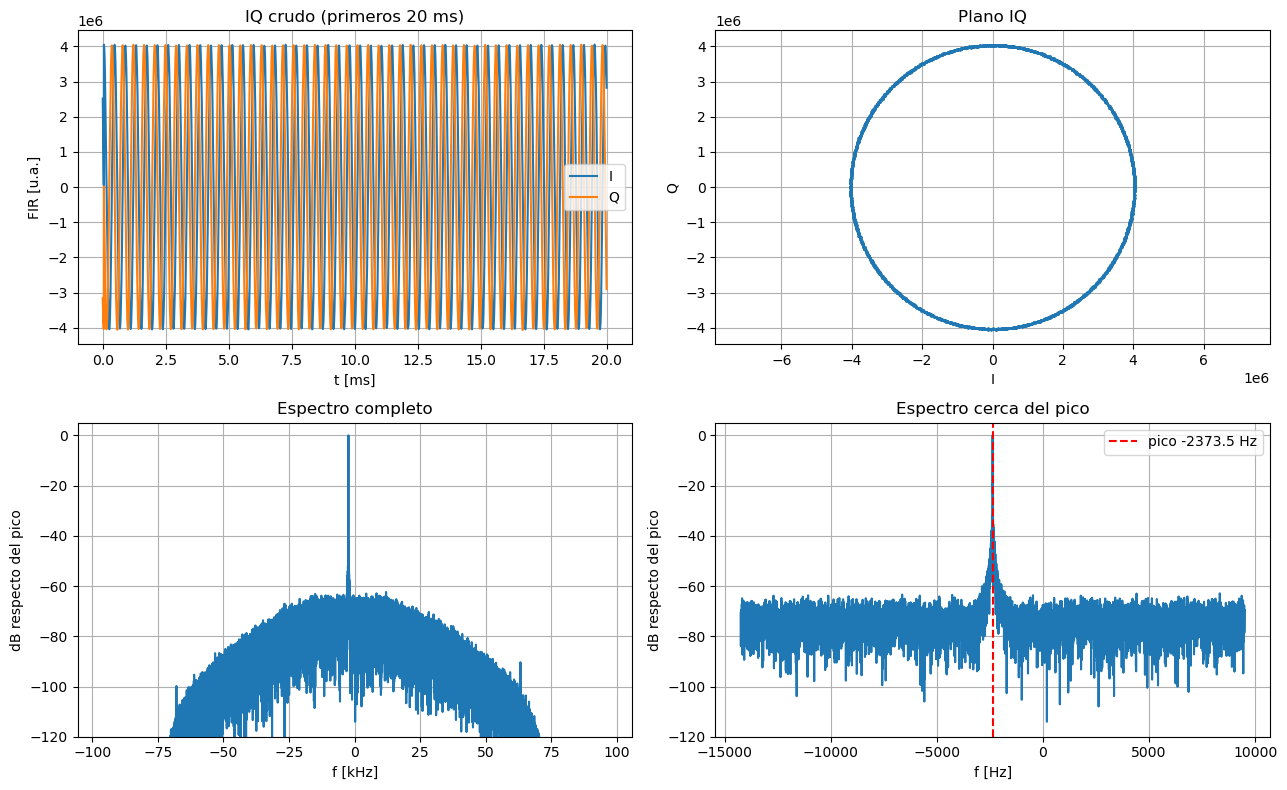

In [45]:
# ============================================================
# Analisis y graficos
# ============================================================
N = len(z)
t = np.arange(N) / FS_IQ

# Espectro (ventana de Hann) y pico con interpolacion parabolica del logaritmo del modulo
Z = np.fft.fftshift(np.fft.fft(z * np.hanning(N)))
f = np.fft.fftshift(np.fft.fftfreq(N, 1 / FS_IQ))
mag = np.abs(Z)
k = int(np.argmax(mag))
d = 0.0
if 0 < k < N - 1:
    a, b, c = np.log(mag[k - 1]), np.log(mag[k]), np.log(mag[k + 1])
    if a - 2 * b + c != 0:
        d = 0.5 * (a - c) / (a - 2 * b + c)
f_pico = f[k] + d * FS_IQ / N

piso = np.mean(mag[np.abs(np.arange(N) - k) > 20] ** 2)      # potencia media lejos del pico
snr_db = 10 * np.log10(mag[k] ** 2 / piso)

# Frecuencia por la pendiente de la fase (vale si el tono domina)
f_fase = np.polyfit(t, np.unwrap(np.angle(z)), 1)[0] / (2 * np.pi)

amp = np.abs(z)
f_esperada = F_TONO_HZ - F_NCO_HZ                           # donde cae el tono si el mezclador resta el NCO
desv = f_pico - f_esperada

print(f"Pico del espectro:   {f_pico:+.2f} Hz   ({snr_db:.1f} dB sobre el piso de ruido, por bin)")
print(f"Pendiente de fase:   {f_fase:+.2f} Hz")
print(f"Esperado (NCO - tono): {f_esperada:+.2f} Hz   -> desviacion {desv:+.2f} Hz = {desv / F_TONO_HZ * 1e6:+.2f} ppm a {F_TONO_HZ / 1e6:g} MHz")
print(f"|IQ|: media {amp.mean():.4g}, variacion {amp.std() / amp.mean() * 100:.2f} %")

if snr_db >= UMBRAL_TONO_DB:
    print(f"[OK] hay un tono: {snr_db:.1f} dB sobre el piso de ruido")
else:
    print(f"[FALLO] no se ve un tono ({snr_db:.1f} dB sobre el piso, se pedian {UMBRAL_TONO_DB}): revisar el generador (161,975 MHz y nivel), "
          "J1, VGAIN, que el LO este enganchado, y que el frontend este alimentado")
if abs(f_pico) > 20e3:
    print("AVISO: el pico esta lejos de 0 Hz, donde el CIC y el FIR atenuan: conviene acercarlo con F_NCO_OFFSET_HZ")
if abs(f_pico) < 3 * FS_IQ / N and F_NCO_OFFSET_HZ == 0:
    print("AVISO: el pico esta a menos de 3 bins de 0 Hz: no se distingue de una componente continua (probar F_NCO_OFFSET_HZ = 5000)")
if abs(f_pico - f_fase) > 2 * FS_IQ / N:
    print("AVISO: el pico del espectro y la pendiente de fase no coinciden: hay mas de un tono o el ruido domina")

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
n_show = min(N, int(0.02 * FS_IQ))
ax[0, 0].plot(t[:n_show] * 1e3, z.real[:n_show], label='I')
ax[0, 0].plot(t[:n_show] * 1e3, z.imag[:n_show], label='Q')
ax[0, 0].set(xlabel='t [ms]', ylabel='FIR [u.a.]', title='IQ crudo (primeros 20 ms)')
ax[0, 0].legend(); ax[0, 0].grid(True)

paso = max(1, N // 4000)
ax[0, 1].plot(z.real[::paso], z.imag[::paso], '.', ms=2)
ax[0, 1].set(xlabel='I', ylabel='Q', title='Plano IQ'); ax[0, 1].set_aspect('equal', 'datalim'); ax[0, 1].grid(True)

ax[1, 0].plot(f / 1e3, 20 * np.log10(mag / mag[k] + 1e-12))
ax[1, 0].set(xlabel='f [kHz]', ylabel='dB respecto del pico', title='Espectro completo', ylim=(-120, 5)); ax[1, 0].grid(True)

ancho = max(2e3, 5 * abs(f_pico))
m = np.abs(f - f_pico) < ancho
ax[1, 1].plot(f[m], 20 * np.log10(mag[m] / mag[k] + 1e-12))
ax[1, 1].axvline(f_pico, color='r', ls='--', label=f'pico {f_pico:+.1f} Hz')
ax[1, 1].set(xlabel='f [Hz]', ylabel='dB respecto del pico', title='Espectro cerca del pico', ylim=(-120, 5)); ax[1, 1].legend(); ax[1, 1].grid(True)

plt.tight_layout()
plt.show()

## Guardar la captura y cerrar (opcional)

In [ ]:
np.savez('captura_iq.npz', i=i, q=q, fs_iq=FS_IQ, f_nco_hz=f_nco_real, f_pico_hz=f_pico, snr_db=snr_db)
sock.close()